# Milestone 4 (extension): Predicting the Failure Type

Model 1 (already built) answers **"will the machine fail?"**. In this notebook we build Model 2, which answers **"if it fails, which type?"**

We train **four separate binary Random Forest models**, one per failure type: `TWF`, `HDF`, `PWF`, `OSF`.
`RNF` (random failure) is not modelled (see Step 7).

**Data used:** only the original file `ai4i2020_original_data.csv` (10,000 rows). The synthetic rows and the cleaned file are *not* used, because their failure-type labels do not follow the physical rules of the original data.

## Step 1: Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, json, os

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, make_scorer)

# Paths (this notebook lives in milestone4/ms4_notebooks)
DATA_PATH   = "../../milestone1/ms1_data/ai4i2020_original_data.csv"   # ORIGINAL file (10,000 rows)
TRAIN_PATH  = "../ms4_data/train_ready_milestone3.csv"                 # used only in Step 9 (Model 1)
TEST_PATH   = "../ms4_data/test_ready_milestone3.csv"
MODELS_DIR  = "../ms4_models"                                          # all saved models go here

RANDOM_STATE = 42

## Step 2: Load the original data and prepare it

Same preparation as Milestone 3, with one difference: we **keep** the five failure-type columns (they become targets), and we keep `Machine failure` only for stratifying the split (it is never a feature).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Sanity check: this must be the ORIGINAL file (339 failures, 19 RNF)
print("Machine failure:", df["Machine failure"].sum())
print(df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())

Machine failure: 339
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [4]:
# 1) Engineered features (same formulas as Milestone 3)
df["Temp_Diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Mechanical_Power_W"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * (2 * np.pi / 60)
df["Strain_Index"] = df["Torque [Nm]"] * df["Tool wear [min]"]

# 2) Type -> ordinal number (L < M < H)
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# 3) Drop identifiers
df = df.drop(columns=["UDI", "Product ID"])

print(df.isnull().sum().sum(), "missing values")
df.head()

0 missing values


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp_Diff,Mechanical_Power_W,Strain_Index
0,1,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,6951.590560,0.0
1,0,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,6826.722724,138.9
2,0,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,7749.387543,247.0
3,0,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,5927.504659,276.5
4,0,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,5897.816608,360.0


## Step 3: Define features and targets

The 9 features are exactly the same as Model 1. Each failure type is its own yes/no question.
A failure can have two types at once (24 rows in this data), so four separate models are used instead of one multi-class model.

In [5]:
features = ["Type", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
            "Temp_Diff", "Mechanical_Power_W", "Strain_Index"]
targets = ["TWF", "HDF", "PWF", "OSF"]          # four models

X = df[features]
Y = df[targets]

print("X:", X.shape, "| Y:", Y.shape)
print("Failures with 2+ types at the same time:", int((df[targets + ["RNF"]].sum(axis=1) >= 2).sum()))
print(Y.sum().rename("positives per type"))

X: (10000, 9) | Y: (10000, 4)
Failures with 2+ types at the same time: 24
TWF     46
HDF    115
PWF     95
OSF     98
Name: positives per type, dtype: int64


## Step 4: Train / test split

80% train, 20% test, stratified on `Machine failure` so both parts contain a similar share of failures.
No `StandardScaler` here: Random Forest does not depend on feature scale.
Important for deployment: these models receive **unscaled** features, while Model 1 receives scaled ones.

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=RANDOM_STATE, stratify=df["Machine failure"]
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nPositives in test set per type:")
print(Y_test.sum())

Train: (8000, 9) | Test: (2000, 9)

Positives in test set per type:
TWF    10
HDF    29
PWF    13
OSF    16
dtype: int64


## Step 5: Train four models (one per failure type)

In [7]:
models = {}
for t in targets:
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, Y_train[t])
    models[t] = rf
    print(f"trained model for {t}")

trained model for TWF
trained model for HDF
trained model for PWF
trained model for OSF


## Step 6: Evaluation (per type)

We use Precision, Recall and F1 for each type, not Accuracy: every type is rare (46 to 115 examples out of 10,000), so a model that always says "no" would already have about 99% accuracy.

Because the test set has only about 9 to 29 positives per type, a single split is noisy, so we add **Stratified 5-fold cross-validation** as a second opinion.

In [8]:
rows = []
for t in targets:
    pred = models[t].predict(X_test)
    rows.append({
        "Type": t,
        "Positives in test": int(Y_test[t].sum()),
        "Precision": precision_score(Y_test[t], pred, zero_division=0),
        "Recall":    recall_score(Y_test[t], pred, zero_division=0),
        "F1":        f1_score(Y_test[t], pred, zero_division=0),
    })
test_results = pd.DataFrame(rows).set_index("Type")
test_results.round(3)

,Positives in test,Precision,Recall,F1
Type,,,,
TWF,10,0.000,0.000,0.000
HDF,29,0.933,0.966,0.949
PWF,13,1.000,1.000,1.000
OSF,16,1.000,1.000,1.000


In [9]:
# Confusion matrices: rows = actual, columns = predicted (0 = no, 1 = yes)
for t in targets:
    cm = confusion_matrix(Y_test[t], models[t].predict(X_test), labels=[0, 1])
    print(f"{t}:  TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

TWF:  TN=1989  FP=1  FN=10  TP=0
HDF:  TN=1969  FP=2  FN=1  TP=28
PWF:  TN=1987  FP=0  FN=0  TP=13
OSF:  TN=1984  FP=0  FN=0  TP=16


In [10]:
# Stratified 5-fold CV on the whole file, separately for each type
scoring = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    make_scorer(recall_score, zero_division=0),
    "f1":        make_scorer(f1_score, zero_division=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for t in targets:
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    s = cross_validate(rf, X, df[t], cv=cv, scoring=scoring)
    cv_rows.append({"Type": t,
                    "CV Precision": s["test_precision"].mean(),
                    "CV Recall":    s["test_recall"].mean(),
                    "CV F1 (mean)": s["test_f1"].mean(),
                    "CV F1 (std)":  s["test_f1"].std()})
cv_results = pd.DataFrame(cv_rows).set_index("Type")
cv_results.round(3)

,CV Precision,CV Recall,CV F1 (mean),CV F1 (std)
Type,,,,
TWF,0.133,0.044,0.063,0.079
HDF,0.920,0.983,0.950,0.028
PWF,0.979,0.989,0.984,0.021
OSF,1.000,0.989,0.995,0.011


,Test F1,CV F1 (mean)
Type,,
TWF,0.000,0.063
HDF,0.949,0.950
PWF,1.000,0.984
OSF,1.000,0.995


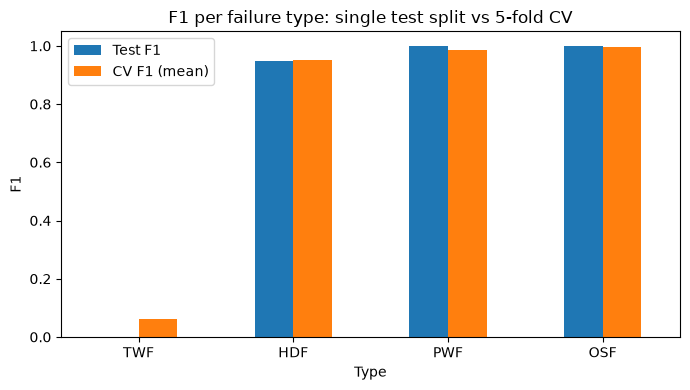

In [11]:
# Side-by-side summary + chart
summary = test_results[["F1"]].rename(columns={"F1": "Test F1"}).join(cv_results[["CV F1 (mean)"]])
display(summary.round(3))

ax = summary.plot(kind="bar", figsize=(7, 4), ylim=(0, 1.05), rot=0)
ax.set_title("F1 per failure type: single test split vs 5-fold CV")
ax.set_ylabel("F1")
plt.tight_layout()
plt.show()

**How to read the results**

- `HDF`, `PWF` and `OSF` are predicted almost perfectly. This is expected: in the original data these failures are produced by clear physical rules (low temperature difference with low speed for `HDF`; power outside a safe range for `PWF`; torque x tool wear above a limit for `OSF`), and the engineered features `Temp_Diff`, `Mechanical_Power_W` and `Strain_Index` encode exactly those quantities.
- `TWF` is weak. Tool-wear failures happen at a random moment inside a wear window of roughly 200 to 240 minutes, so the readings cannot pinpoint them. With only 46 examples this is a limit of the data, not a bug.
- Test-set counts are tiny, so trust the CV column more than a single split.

## Step 7: RNF is not modelled

`RNF` (random failure) is a random event by the design of the dataset (19 examples out of 10,000), so it cannot be predicted from the sensor readings. We state this openly instead of training a model that would only memorise noise.

In [12]:
print("RNF examples in the original data:", int(df["RNF"].sum()))
print("Failures with NO type flag at all:", int(((df["Machine failure"] == 1) & (df[targets + ["RNF"]].sum(axis=1) == 0)).sum()))

RNF examples in the original data: 19
Failures with NO type flag at all: 9


## Step 8: Save the models

One file per failure type, plus the feature list so the app uses the same column order.
Model 1 (failure yes/no) is saved in Step 9.

In [13]:
os.makedirs(MODELS_DIR, exist_ok=True)

for t, model in models.items():
    joblib.dump(model, f"{MODELS_DIR}/model_{t}.joblib")

with open(f"{MODELS_DIR}/type_model_features.json", "w") as f:
    json.dump(features, f)

import sklearn
print("scikit-learn version used:", sklearn.__version__)
print("Saved in", MODELS_DIR, ":", [f"model_{t}.joblib" for t in models] + ["type_model_features.json"])

scikit-learn version used: 1.9.1
Saved in ../ms4_models : ['model_TWF.joblib', 'model_HDF.joblib', 'model_PWF.joblib', 'model_OSF.joblib', 'type_model_features.json']


In [14]:
# Quick reload check: loaded models must give the same predictions
for t in targets:
    reloaded = joblib.load(f"{MODELS_DIR}/model_{t}.joblib")
    assert (reloaded.predict(X_test) == models[t].predict(X_test)).all()
print("All 4 models reload correctly.")

All 4 models reload correctly.


## Step 9: Save Model 1 (failure yes/no)

The linking code needs **six** files. Four are saved above, `scaler_milestone3.joblib` already exists, and the last one is Model 1.

Model 1 is the Random Forest selected in Milestone 4 (same settings: 100 trees, `class_weight="balanced"`, `random_state=42`), trained on the full prepared training file `train_ready_milestone3.csv` (scaled features, as in Milestone 4). Rebuilding it here means this notebook does not depend on the state of the Milestone 4 notebook.

In [15]:
from sklearn.metrics import f1_score, recall_score, precision_score

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

X_tr1, y_tr1 = train_df.drop("Machine failure", axis=1), train_df["Machine failure"]
X_te1, y_te1 = test_df.drop("Machine failure", axis=1),  test_df["Machine failure"]

# The column order must match the type models and the linking code
assert list(X_tr1.columns) == features, "Column order differs from `features`"

model_failure = RandomForestClassifier(n_estimators=100, random_state=42,
                                       class_weight="balanced", n_jobs=-1)
model_failure.fit(X_tr1, y_tr1)

pred1 = model_failure.predict(X_te1)
print("Model 1 on the Milestone 3 test set:")
print("  Precision:", round(precision_score(y_te1, pred1), 4))
print("  Recall   :", round(recall_score(y_te1, pred1), 4))
print("  F1       :", round(f1_score(y_te1, pred1), 4), "(Milestone 4 reported about 0.93)")

joblib.dump(model_failure, f"{MODELS_DIR}/model_failure.joblib")
print("Saved:", f"{MODELS_DIR}/model_failure.joblib")

Model 1 on the Milestone 3 test set:
  Precision: 0.9213
  Recall   : 0.9278
  F1       : 0.9246 (Milestone 4 reported about 0.93)
Saved: ../ms4_models/model_failure.joblib


In [16]:
# Final check: are all six files ready for predict.py?
needed = ["model_failure.joblib", "scaler_milestone3.joblib",
          "model_TWF.joblib", "model_HDF.joblib", "model_PWF.joblib", "model_OSF.joblib"]
for name in needed:
    ok = os.path.exists(f"{MODELS_DIR}/{name}")
    print("OK     " if ok else "MISSING", name)

OK      model_failure.joblib
MISSING scaler_milestone3.joblib
OK      model_TWF.joblib
OK      model_HDF.joblib
OK      model_PWF.joblib
OK      model_OSF.joblib
